# Clasificador de residuos
**Luis Eduardo Sagastume Rodríguez · Computación en la Nube**

Se clasifican fotografías de un solo residuo en cuatro clases: cartón, papel, plástico y vidrio. Usamos [TrashNet](https://github.com/garythung/trashnet), de Gary Thung y Mindy Yang. Se excluyen las carpetas de metal y basura general.

In [1]:
import json
import os
import shutil
from pathlib import Path
from zipfile import ZipFile
from urllib.request import urlretrieve

os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '4')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '2')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

SEED = 42
SIZE = (96, 96)
CLASES = {'cardboard': 'Cartón', 'paper': 'Papel', 'plastic': 'Plástico', 'glass': 'Vidrio'}
keras.utils.set_random_seed(SEED)

data = Path('datos')
data.mkdir(exist_ok=True)
out = Path('resultados')
out.mkdir(exist_ok=True)
root = data / 'dataset-resized'
if not root.is_dir():
    archive = data / 'dataset-resized.zip'
    if not archive.exists():
        urlretrieve('https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip', archive)
    with ZipFile(archive) as z:
        z.extractall(data)

records = [(path, idx) for idx, folder in enumerate(CLASES)
           for path in sorted((root / folder).glob('*.jpg'))]
df = pd.DataFrame(records, columns=['ruta', 'etiqueta'])
assert set(df.etiqueta) == set(range(len(CLASES)))
names = list(CLASES.values())
df.assign(clase=df.etiqueta.map(dict(enumerate(names)))).groupby('clase').size().rename('Fotos')

clase
Cartón      403
Papel       594
Plástico    482
Vidrio      501
Name: Fotos, dtype: int64

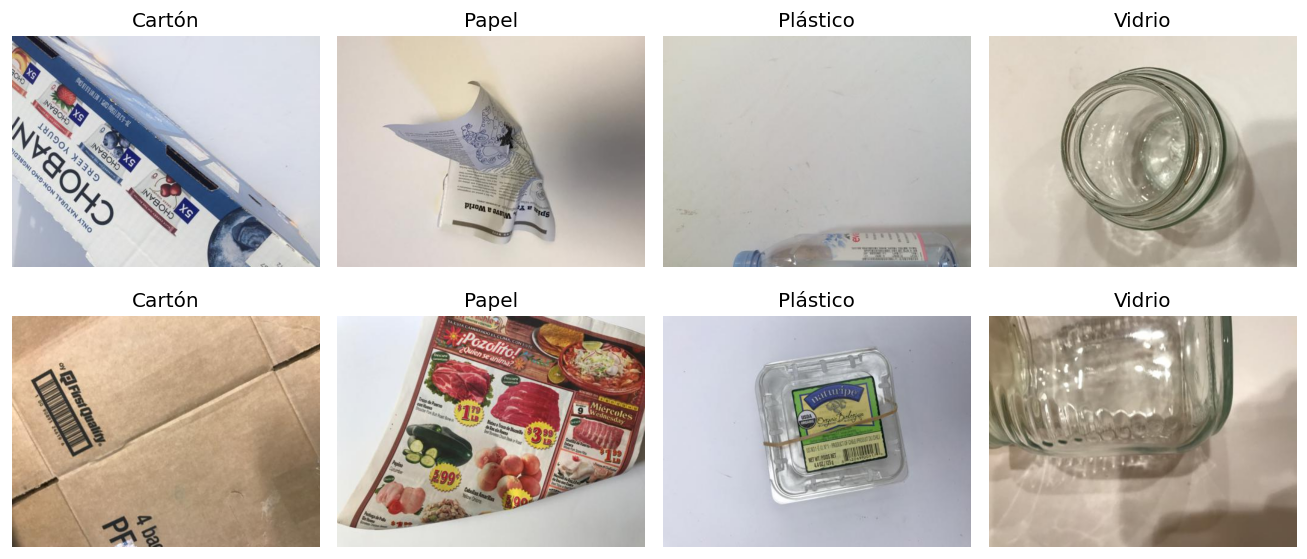

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for idx, name in enumerate(names):
    sample = df[df.etiqueta == idx].sample(2, random_state=SEED)
    for ax, path in zip(axes[:, idx], sample.ruta):
        with Image.open(path) as img:
            ax.imshow(img)
        ax.set_title(name)
        ax.axis('off')
fig.tight_layout()
plt.show()

## Separación y preparación
Reservamos dos fotografías por clase para una prueba adicional de la aplicación. El resto se divide de forma estratificada en aproximadamente 70 % para entrenamiento, 15 % para validación y 15 % para prueba. Aplicamos orientación EXIF, RGB y redimensionado bilineal a 96 × 96 píxeles. La normalización de 0–255 a −1–1 se incorpora dentro del modelo.

In [3]:
extra = pd.concat([group.sample(2, random_state=SEED)
                   for _, group in df.groupby('etiqueta')])
pool = df.drop(extra.index)
train, rest = train_test_split(pool, test_size=0.30, stratify=pool.etiqueta, random_state=SEED)
val, test = train_test_split(rest, test_size=0.50, stratify=rest.etiqueta, random_state=SEED)
assert len(set(train.index) | set(val.index) | set(test.index) | set(extra.index)) == len(df)

def prepare(frame):
    images = []
    for path in frame.ruta:
        with Image.open(path) as img:
            rgb = ImageOps.exif_transpose(img).convert('RGB')
            images.append(np.asarray(rgb.resize(SIZE, Image.Resampling.BILINEAR), dtype=np.float32))
    return np.stack(images), frame.etiqueta.to_numpy()

counts = pd.DataFrame({label: part.etiqueta.value_counts()
                       for label, part in [('Entrenamiento', train), ('Validación', val),
                                           ('Prueba', test), ('Fotos adicionales', extra)]})
counts.index = [names[i] for i in counts.index]
counts.loc['Total'] = counts.sum()
counts

,Entrenamiento,Validación,Prueba,Fotos adicionales
Cartón,281,60,60,2
Papel,414,89,89,2
Plástico,336,72,72,2
Vidrio,349,75,75,2
Total,1380,296,296,8


## Entrenamiento
MobileNetV2 con pesos de ImageNet extrae rasgos visuales. Congelamos esa base y entrenamos una capa de clasificación de cuatro salidas. La validación determina la época con menor pérdida. El conjunto de prueba se usa al final.

In [4]:
weights = keras.utils.get_file(
    'mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5',
    'https://storage.googleapis.com/tensorflow/keras-applications/mobilenet_v2/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5',
)
base = keras.applications.MobileNetV2(input_shape=(*SIZE, 3), include_top=False,
                                     weights=weights, pooling='avg')
base.trainable = False
pixels = keras.Input(shape=(*SIZE, 3))
normalized = keras.layers.Rescaling(1 / 127.5, offset=-1)(pixels)
features = keras.Model(pixels, base(normalized, training=False), name='rasgos')
head = keras.Sequential([
    keras.Input(shape=(1280,)),
    keras.layers.Dropout(0.20),
    keras.layers.Dense(len(names), activation='softmax'),
], name='clasificacion')
head.compile(optimizer=keras.optimizers.Adam(0.001), loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])
x_train, y_train = prepare(train)
x_val, y_val = prepare(val)
x_test, y_test = prepare(test)
z_train = features.predict(x_train, batch_size=32, verbose=0)
z_val = features.predict(x_val, batch_size=32, verbose=0)
history = head.fit(z_train, y_train, validation_data=(z_val, y_val), batch_size=64,
                   epochs=25, verbose=2,
                   callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                                            restore_best_weights=True)])
model = keras.Model(pixels, head(features(pixels)), name='clasificador_residuos')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/25
22/22 - 1s - 23ms/step - accuracy: 0.4536 - loss: 1.3920 - val_accuracy: 0.7196 - val_loss: 0.7427
Epoch 2/25
22/22 - 0s - 5ms/step - accuracy: 0.7341 - loss: 0.6792 - val_accuracy: 0.7703 - val_loss: 0.5645
Epoch 3/25
22/22 - 0s - 5ms/step - accuracy: 0.7957 - loss: 0.5341 - val_accuracy: 0.8108 - val_loss: 0.4975
Epoch 4/25
22/22 - 0s - 5ms/step - accuracy: 0.8362 - loss: 0.4363 - val_accuracy: 0.8378 - val_loss: 0.4691
Epoch 5/25
22/22 - 0s - 5ms/step - accuracy: 0.8572 - loss: 0.3812 - val_accuracy: 0.8514 - val_loss: 0.4413
Epoch 6/25
22/22 - 0s - 5ms/step - accuracy: 0.8746 - loss: 0.3387 - val_accuracy: 0.8480 - val_loss: 0.4196
Epoch 7/25
22/22 - 0s - 4ms/step - accuracy: 0.8935 - loss: 0.3025 - val_accuracy: 0.8547 - val_loss: 0.4061
Epoch 8/25
22/22 - 0s - 4ms/step - accuracy: 0.9043 - loss: 0.2801 - val_accuracy: 0.8581 - val_loss: 0.3917
Epoch 9/25
22/22 - 0s - 4ms/step - accuracy: 0.9094 - loss: 0.2660 - val_accur

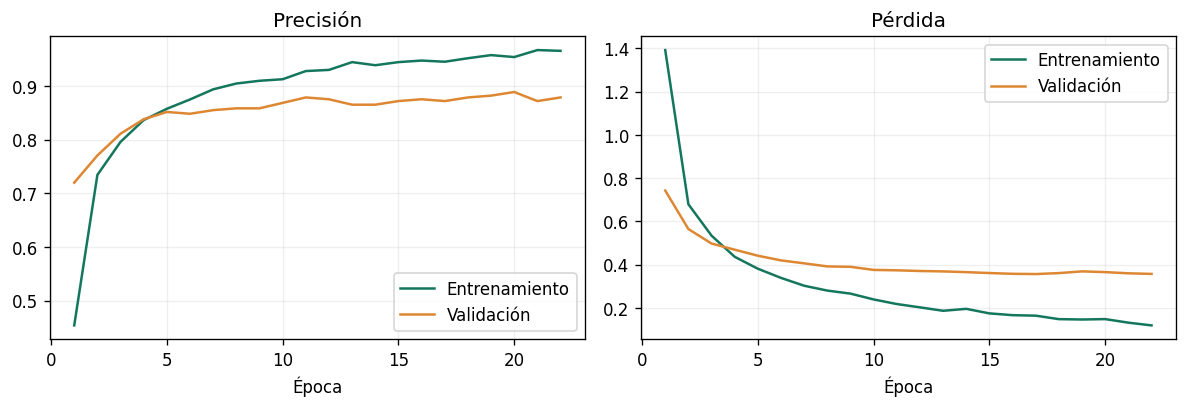

In [5]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, key, title in zip(axes, ('accuracy', 'loss'), ('Precisión', 'Pérdida')):
    ax.plot(hist.index + 1, hist[key], label='Entrenamiento', color='#14775d')
    ax.plot(hist.index + 1, hist['val_' + key], label='Validación', color='#de8732')
    ax.set(title=title, xlabel='Época')
    ax.grid(alpha=.2)
    ax.legend()
fig.tight_layout()
fig.savefig(out / 'entrenamiento.png', dpi=175)
plt.show()

Prueba: 251/296 aciertos (84.80%). Pérdida: 0.4261.
              precision    recall  f1-score   support

      Cartón       0.89      0.85      0.87        60
       Papel       0.87      0.92      0.90        89
    Plástico       0.83      0.74      0.78        72
      Vidrio       0.80      0.87      0.83        75

    accuracy                           0.85       296
   macro avg       0.85      0.84      0.85       296
weighted avg       0.85      0.85      0.85       296



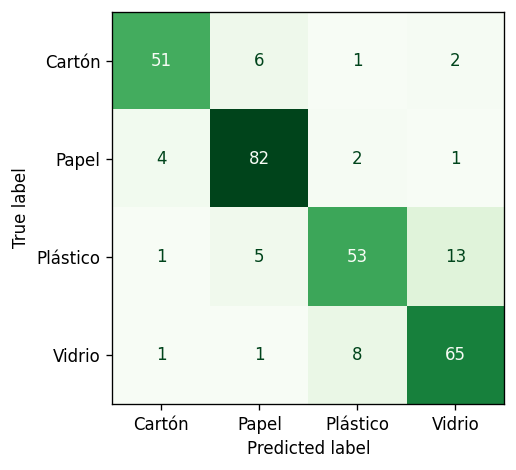

144

In [6]:
p_test = model.predict(x_test, batch_size=32, verbose=0)
pred = p_test.argmax(axis=1)
acc = (pred == y_test).mean()
loss = float(keras.losses.sparse_categorical_crossentropy(y_test, p_test).numpy().mean())
print(f'Prueba: {sum(pred == y_test)}/{len(test)} aciertos ({acc:.2%}). Pérdida: {loss:.4f}.')
print(classification_report(y_test, pred, target_names=names, zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=names, ax=ax,
                                       colorbar=False, cmap='Greens')
fig.tight_layout()
plt.show()
(out / 'metricas.json').write_text(json.dumps({'accuracy': float(acc), 'loss': loss,
    'hits': int(sum(pred == y_test)), 'test': len(test), 'train': len(train), 'val': len(val),
    'epochs': len(hist), 'best_epoch': int(hist.val_loss.idxmin() + 1)}), encoding='utf-8')

In [7]:
model.save('modelo.keras')
Path('clases.json').write_text(json.dumps(names, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
samples = out / 'fotos'
samples.mkdir(exist_ok=True)
for path in extra.ruta:
    shutil.copy2(path, samples / path.name)
extra.assign(clase=extra.etiqueta.map(dict(enumerate(names))),
             archivo=extra.ruta.map(lambda path: path.name))[['archivo', 'clase']].to_csv(
                 out / 'fotos_reservadas.csv', index=False)
print('Exportados modelo.keras y clases.json.')
print('También se reservaron ocho fotos para verificar inferencia en la aplicación.')

Exportados modelo.keras y clases.json.
También se reservaron ocho fotos para verificar inferencia en la aplicación.
